# India Drought Analysis (State: Odisha)
## Notebook 01 (Week 2): Data loading, cleaning and first EDA – Odisha only

| | |
|---|---|
| **Course** | CUTM1018 – Data Analysis and Visualization with Python |
| **Faculty** | Chandra Sekhar Jena |
| **Students** | Piyush Patnaik (250301370280), Vegulla Virendra Kaushik (250301370267) |
| **Dataset** | Drought Atlas of India 1901–2025, v2 (Chuphal, Kushwaha, Aadhar & Mishra; IIT Gandhinagar / IIT Jodhpur) – https://zenodo.org/records/20368514 |
| **Scope** | Odisha statewide series + 30 Odisha districts |

### Introduction
Drought is a recurring problem in India, and Odisha (especially its western districts) is often described as drought-prone.
In this project we use the **Standardised Precipitation Evapotranspiration Index (SPEI)** from the Drought Atlas of India
to study how often droughts happen in Odisha, how severe they are, and where in Odisha they happen.

SPEI is a standardised index (like a z-score): 0 means normal conditions, negative values mean drier than normal and
positive values mean wetter than normal. Following our proposal, a month is called a **drought month when SPEI ≤ −1**.

In this notebook we:
1. describe and load the Odisha statewide file and the 30 Odisha district files,
2. check data quality (missing values, sentinel values, duplicates, date gaps, name problems),
3. clean the data and explain every decision,
4. add useful features (year, month, season, drought flag, severity class),
5. check outliers with the IQR method,
6. do a first round of EDA with a few charts, and
7. save the cleaned tables to `data/clean/` and the charts to `reports/figures/`.

## 1. Setup
We import the libraries, set the folder paths and fix a few constants that are used through the notebook.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings so tables are easy to read
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# The notebook sits in notebooks/, so the project folder is one level up
# Find the project folder: walk up from the current folder until we see data/clean
# (works if Jupyter was started in the project folder or in notebooks/)
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").is_dir()), Path.cwd())
if not (PROJECT / "data" / "clean").is_dir():
    raise FileNotFoundError("Cannot find the project folder (the folder that contains data/clean). Open this notebook from inside the "
                            "unzipped project folder and start Jupyter there - a single notebook file cannot run on its own. "
                            "See RUN_ON_YOUR_DEVICE.md.")
RAW = PROJECT / "data" / "raw" / "DroughtAtlas_v2"
ZSCORE = RAW / "Z-score"
CLEAN = PROJECT / "data" / "clean"
FIG = PROJECT / "reports" / "figures"
CLEAN.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# Project constants
DROUGHT_THRESHOLD = -1.0   # drought month if SPEI <= -1 (from our proposal)
SPEI_COLS = ["spei_1", "spei_4", "spei_12"]

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Raw data folder exists:", ZSCORE.is_dir())

# Guard: this notebook needs the raw atlas data (not included in the run-on-device package)
if not (ZSCORE / "States").is_dir():
    raise RuntimeError("Raw atlas data not found at " + str(RAW) + ".\n"
                       "Notebook 01 needs it. See data/raw/HOW_TO_GET_RAW_DATA.txt for how to download it.\n"
                       "You do NOT need it for notebooks 02 and 04 or for the dashboard - they use data/clean/ only.")

pandas 3.0.6 | numpy 2.5.3
Raw data folder exists: True


## 2. Dataset description

### 2.1 What is inside the downloaded zip
The file `DroughtAtlas_v2.zip` is about 3 GB. We listed its contents (with `unzip -l`) before extracting anything:

| Folder / file | What it contains | Files | Size (uncompressed) | Used in this project? |
|---|---|---|---|---|
| `Gridded_SPEI/` | SPEI for every 0.05° grid cell (`data_<lat>_<lon>`) | 115,394 | ~6.2 GB | **No** – too big, and the proposal says not to use it |
| `Z-score/India/India` | All-India average SPEI | 1 | 47 KB | **No** (not needed) |
| `Z-score/States/` | State average SPEI, one file per state ID | 36 | 1.7 MB | **Only the Odisha file** (ID 30) |
| `Z-score/Districts/` | District average SPEI, one file per district ID | 732 | 34.6 MB | **Only the 30 Odisha districts** |
| `Z-score/Talukas/` | Sub-district (taluka) average SPEI | 4,639 | 219 MB | No (not extracted) |
| `Z-score/India_States.xlsx`, `India_Districts.xlsx` | ID → name lookup tables | 2 | 0.2 MB | **Yes** (to find the Odisha IDs and names) |
| `Administrative-Boundaries_Shapefile/` | State / district / sub-district / country shapefiles | 27 | 240 MB | Odisha districts only (for maps) |
| `DroughtAtlas/` | Yearly drought maps as PNG images (1901–2024) | 124 | 211 MB | No |
| `readme` | Description of the folders and file layout | 1 | 4 KB | Yes (read it) |

We extracted only `readme`, the `Z-score` folders, the lookup Excel files and the state/district shapefiles into `data/raw/`
(about 124 MB). The code below lists what is present in our `data/raw` folder; the notebook then **reads only the Odisha state file (ID 30) and the 30 Odisha district files**; the gridded and other files are not used.

In [2]:
# Count the files and size of each extracted folder
rows = []
for folder in sorted(p for p in RAW.rglob("*") if p.is_dir()):
    files = [f for f in folder.iterdir() if f.is_file()]
    if files:
        rows.append({"folder": str(folder.relative_to(RAW)),
                     "n_files": len(files),
                     "size_MB": round(sum(f.stat().st_size for f in files) / 1e6, 2)})
inventory = pd.DataFrame(rows)
inventory

,folder,n_files,size_MB
0,Administrative-Boundaries_Shapefile,12,92.04
1,Z-score,3,0.16
2,Z-score/Districts,732,34.62
3,Z-score/India,1,0.05
4,Z-score/States,36,1.69


### 2.2 File format (from the `readme` and our own check)
The readme says each Z-score file has **5 columns: Year, Month, SPEI-1month, SPEI-4month, SPEI-12month**.
There is **no header row**, the values are separated by spaces, and missing values are written as the text `NaN`.
We first read the lookup tables to find the ID of Odisha and of its districts, then look at the first raw lines of the Odisha file.

In [3]:
def fix_name(name):
    # Repair the corrupted characters in atlas names
    name = str(name).strip().upper()
    name = name.replace("|", "I").replace("@", "U")
    name = re.sub(r"\s+", " ", name)
    name = name.replace(" )", ")")
    return name


def title_name(name):
    # 'JAMMU AND KASHMIR' -> 'Jammu and Kashmir'
    return re.sub(r"\bAnd\b", "and", name.title())


# Lookup tables (ID -> name): they list all of India, we only use the Odisha rows
states_lu = pd.read_excel(ZSCORE / "India_States.xlsx")
districts_lu = pd.read_excel(ZSCORE / "India_Districts.xlsx")

odisha_state_rows = states_lu[states_lu["State"].apply(fix_name) == "ODISHA"]
assert len(odisha_state_rows) == 1
ODISHA_STATE_ID = int(odisha_state_rows["ID"].iloc[0])
odisha_districts_lu = districts_lu[districts_lu["State"].apply(fix_name) == "ODISHA"].copy()
print("Odisha state ID:", ODISHA_STATE_ID, "| Odisha districts in the lookup:", len(odisha_districts_lu))

odisha_file = ZSCORE / "States" / f"data_statewise_id_{ODISHA_STATE_ID}"
with open(odisha_file) as f:
    for _ in range(6):
        print(repr(f.readline()))

Odisha state ID: 30 | Odisha districts in the lookup: 30
'1901 1 1.4937 NaN NaN\n'
'1901 2 1.7757 NaN NaN\n'
'1901 3 -0.21321 NaN NaN\n'
'1901 4 0.63873 1.5741 NaN\n'
'1901 5 0.14834 1.0397 NaN\n'
'1901 6 -2.0914 -1.4493 NaN\n'


So the files are plain text, space separated, without a header. The timescales available are **SPEI-1, SPEI-4 and SPEI-12**
(there is no SPEI-3 or SPEI-6 in this version). We will use these column names:

| Column | Type | Meaning |
|---|---|---|
| `year` | int | Calendar year (1901–2025) |
| `month` | int | Month number (1 = January … 12 = December) |
| `spei_1` | float | 1-month SPEI: dryness of that single month (meteorological drought) |
| `spei_4` | float | 4-month SPEI: dryness of the 4 months ending in this month. The September value covers June–September, i.e. the summer monsoon (JJAS) |
| `spei_12` | float | 12-month SPEI: dryness of the last 12 months. The December value describes the whole calendar year |

The names of the state and districts are **not** inside these files. They come from the lookup files
`India_States.xlsx` (columns `ID`, `State`) and `India_Districts.xlsx` (columns `ID`, `State`, `District`).

## 3. Loading the data
We write one small function to read a single SPEI file and use it for the Odisha statewide file and the 30 Odisha district files.
The ID number is taken from the file name (for example `data_statewise_id_30` → 30).

In [4]:
def load_spei_file(path):
    # Space separated, no header row; pandas reads the text 'NaN' as a missing value automatically
    return pd.read_csv(path, sep=r"\s+", header=None, names=["year", "month"] + SPEI_COLS)


# Odisha statewide series
state_raw = load_spei_file(odisha_file)
state_raw.insert(0, "state_id", ODISHA_STATE_ID)

# The 30 Odisha district series
frames = []
for dist_id in odisha_districts_lu["ID"]:
    path = ZSCORE / "Districts" / f"data_distwise_id_{dist_id}"
    df = load_spei_file(path)
    df["district_id"] = int(dist_id)
    frames.append(df)
district_raw = pd.concat(frames, ignore_index=True)

print("Odisha statewide series :", state_raw.shape)
print("District series         :", district_raw.shape, "from", district_raw["district_id"].nunique(), "files")

Odisha statewide series : (1500, 6)
District series         : (45000, 6) from 30 files


In [5]:
state_raw.head()

,state_id,year,month,spei_1,spei_4,spei_12
0,30,1901,1,1.49370,NaN,NaN
1,30,1901,2,1.77570,NaN,NaN
2,30,1901,3,-0.21321,NaN,NaN
3,30,1901,4,0.63873,1.5741,NaN
4,30,1901,5,0.14834,1.0397,NaN


In [6]:
district_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   year         45000 non-null  int64  
 1   month        45000 non-null  int64  
 2   spei_1       45000 non-null  float64
 3   spei_4       44910 non-null  float64
 4   spei_12      44670 non-null  float64
 5   district_id  45000 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 2.1 MB


## 4. Data quality checks
Before changing anything we check the raw Odisha data for: missing values, sentinel/impossible values, duplicates,
gaps in the dates, mismatches between files and lookup tables, and problems in the names.

### 4.1 Missing values

In [7]:
missing = pd.DataFrame({
    "state_missing": state_raw[SPEI_COLS].isna().sum(),
    "state_missing_%": (state_raw[SPEI_COLS].isna().mean() * 100).round(2),
    "district_missing": district_raw[SPEI_COLS].isna().sum(),
    "district_missing_%": (district_raw[SPEI_COLS].isna().mean() * 100).round(2),
})
missing

,state_missing,state_missing_%,district_missing,district_missing_%
spei_1,0,0.00,0,0.00
spei_4,3,0.20,90,0.20
spei_12,11,0.73,330,0.73


In [8]:
# (a) Completely empty series? Number of non-missing SPEI-1 values in each series; 0 would mean the whole file is empty
valid_dist = district_raw.groupby("district_id")["spei_1"].count()
print("Odisha statewide non-missing SPEI-1 values:", int(state_raw["spei_1"].count()))
print("Empty district series:", valid_dist[valid_dist == 0].index.tolist())

# (b) Where are the missing values? (only SPEI-4 / SPEI-12 at the start of the record are expected)
for name, df in [("state", state_raw), ("districts", district_raw)]:
    for col in SPEI_COLS:
        gaps = df[df[col].isna()]
        where = sorted(set(zip(gaps["year"], gaps["month"])))
        print(f"{name:9s} {col}: {len(gaps)} missing values, found only at (year, month) = {where}")

Odisha statewide non-missing SPEI-1 values: 1500
Empty district series: []
state     spei_1: 0 missing values, found only at (year, month) = []
state     spei_4: 3 missing values, found only at (year, month) = [(1901, 1), (1901, 2), (1901, 3)]
state     spei_12: 11 missing values, found only at (year, month) = [(1901, 1), (1901, 2), (1901, 3), (1901, 4), (1901, 5), (1901, 6), (1901, 7), (1901, 8), (1901, 9), (1901, 10), (1901, 11)]
districts spei_1: 0 missing values, found only at (year, month) = []
districts spei_4: 90 missing values, found only at (year, month) = [(1901, 1), (1901, 2), (1901, 3)]
districts spei_12: 330 missing values, found only at (year, month) = [(1901, 1), (1901, 2), (1901, 3), (1901, 4), (1901, 5), (1901, 6), (1901, 7), (1901, 8), (1901, 9), (1901, 10), (1901, 11)]


SPEI-4 needs the previous 4 months and SPEI-12 needs the previous 12 months. In January 1901 there is no earlier data,
so SPEI-4 cannot be calculated for January–March 1901 and SPEI-12 cannot be calculated for January–November 1901.
These gaps are **structural** (built into how the index works), not data errors. SPEI-1 has no gaps at all, and no Odisha series is empty.

### 4.2 Sentinel values and impossible values
Some climate datasets write missing values as −999 or 9999. SPEI is a standardised index, so real values should
mostly lie between about −3 and +3; anything beyond ±5 would be suspicious.

In [9]:
for name, df in [("state", state_raw), ("district", district_raw)]:
    values = df[SPEI_COLS]
    print(f"{name:8s} | min = {values.min().min():7.3f} | max = {values.max().max():6.3f} | "
          f"values <= -99 or >= 99: {int((values.abs() >= 99).sum().sum())} | "
          f"|value| > 5: {int((values.abs() > 5).sum().sum())}")

# Year and month should also be in a valid range
print("Years :", state_raw["year"].min(), "to", state_raw["year"].max())
print("Months:", sorted(state_raw["month"].unique().tolist()))

state    | min =  -3.146 | max =  2.926 | values <= -99 or >= 99: 0 | |value| > 5: 0
district | min =  -3.619 | max =  3.256 | values <= -99 or >= 99: 0 | |value| > 5: 0
Years : 1901 to 2025
Months: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


No sentinel values (−999 / 9999) and no values beyond ±5 were found. Missing values are stored only as `NaN`,
which pandas already understands. Years run from 1901 to 2025 and months are 1–12.

### 4.3 Duplicates
We check (1) duplicate rows for the same area and month, (2) duplicate IDs or names in the Odisha lookup, and
(3) whether two different areas have exactly the same SPEI series (which could mean a file was copied by mistake).

In [10]:
print("Duplicate (state_id, year, month) rows   :", state_raw.duplicated(["state_id", "year", "month"]).sum())
print("Duplicate (district_id, year, month) rows:", district_raw.duplicated(["district_id", "year", "month"]).sum())
print("Duplicate IDs in the Odisha district lookup :", odisha_districts_lu["ID"].duplicated().sum())
print("Duplicate district names (Odisha)           :", odisha_districts_lu["District"].duplicated().sum())

# Identical series check: put each district in its own column and compare columns
wide_d = district_raw.pivot(index=["year", "month"], columns="district_id", values="spei_1")
print("Districts with an identical SPEI-1 series to another district:", wide_d.T.duplicated().sum())
# Is the statewide series identical to any district?
print("Districts identical to the statewide series:", int((wide_d.sub(state_raw.set_index(["year", "month"])["spei_1"], axis=0).abs().max() == 0).sum()))

Duplicate (state_id, year, month) rows   : 0
Duplicate (district_id, year, month) rows: 0
Duplicate IDs in the Odisha district lookup : 0
Duplicate district names (Odisha)           : 0
Districts with an identical SPEI-1 series to another district: 0
Districts identical to the statewide series: 0


### 4.4 Date coverage and gaps
Every series should have one row per month from January 1901 to December 2025, i.e. 125 × 12 = 1500 rows.

In [11]:
expected_months = pd.period_range("1901-01", "2025-12", freq="M")
print("Expected number of months:", len(expected_months))


def check_coverage(df, id_col):
    # For each area: number of rows, first and last month, and how many expected months are missing
    out = []
    for area_id, g in df.groupby(id_col):
        periods = pd.PeriodIndex(pd.to_datetime(g[["year", "month"]].assign(day=1)), freq="M")
        out.append({id_col: area_id, "rows": len(g), "first": periods.min(), "last": periods.max(),
                    "missing_months": len(expected_months.difference(periods))})
    return pd.DataFrame(out)


cov_state = check_coverage(state_raw, "state_id")
cov_dist = check_coverage(district_raw, "district_id")
print("State file    : rows =", cov_state["rows"].tolist(), "| missing months =", cov_state["missing_months"].tolist())
print("District files: rows per file =", cov_dist["rows"].unique(), "| files with missing months =", (cov_dist["missing_months"] > 0).sum())

Expected number of months: 1500


State file    : rows =

 [1500] | missing months = [0]
District files: rows per file = [1500] | files with missing months = 0


### 4.5 Do the files match the lookup tables?

In [12]:
print("Odisha district IDs in the lookup but with no file:", sorted(set(odisha_districts_lu["ID"]) - set(district_raw["district_id"])))
print("Odisha district files with no lookup entry        :", sorted(set(district_raw["district_id"]) - set(odisha_districts_lu["ID"])))
print("Odisha districts in the lookup:", len(odisha_districts_lu))

Odisha district IDs in the lookup but with no file: []
Odisha district files with no lookup entry        : []
Odisha districts in the lookup: 30


### 4.6 Name problems
While reading the lookup tables we noticed strange characters inside some names, for example `N@APARHA`. It looks like the letters
**I** and **U** (probably with long-vowel marks such as Ī / Ū in the original file) were saved as `|` and `@`.
Let us find all Odisha names that contain anything other than capital letters, spaces and normal punctuation.

In [13]:
odd_pattern = r"[^A-Z &\-\.\(\),]"   # anything that is not a capital letter, space or & - . ( ) ,

odd_districts = odisha_districts_lu[odisha_districts_lu["District"].str.contains(odd_pattern, regex=True)]
print("Odisha district names with odd characters:", len(odd_districts))
display(odd_districts)
print("Odd characters found:", odisha_districts_lu["District"].str.findall(odd_pattern).explode().dropna().value_counts().to_dict())
print("Odisha state name in the file:", states_lu.loc[states_lu["ID"] == ODISHA_STATE_ID, "State"].iloc[0])
# Odisha districts as written in the lookup file
odisha_districts_lu.sort_values("District")["District"].tolist()

Odisha district names with odd characters: 2


,ID,State,District
250,251,ODISHA,MAY@RBHANJ
276,277,ODISHA,N@APARHA


Odd characters found: {'@': 2}
Odisha state name in the file: ODISHA


['ANUGUL',
 'BALASORE (BALESHWAR)',
 'BARAGARH',
 'BAUDH (BAUDA)',
 'BHADRAK',
 'BOLANGIR (BALANGIR)',
 'CUTTACK',
 'DEOGARH',
 'DHENKANAL',
 'GAJAPATI',
 'GANJAM',
 'JAGATSINGHPUR',
 'JAJAPUR',
 'JHARSUGUDA',
 'KALAHANDI',
 'KANDHAMAL',
 'KENDRAPARHA',
 'KEONJHAR (KENDUJHAR)',
 'KHORDHA',
 'KORAPUT',
 'MALKANGIRI',
 'MAY@RBHANJ',
 'N@APARHA',
 'NABARANGAPUR',
 'NAYAGARH',
 'PURI',
 'RAYAGARHA',
 'SAMBALPUR',
 'SUBARNAPUR',
 'SUNDARGARH']

**Summary of quality problems found (Odisha only)**

| Check | Result | What we will do |
|---|---|---|
| Fully empty series | none | nothing to do |
| NaN at the start of SPEI-4 / SPEI-12 | Jan–Mar 1901 (SPEI-4) and Jan–Nov 1901 (SPEI-12) only | Keep as NaN, do **not** fill (structural, explained above) |
| Sentinel values (−999 etc.) | none | nothing to do |
| Duplicate rows / IDs | none | nothing to do |
| Missing months | none | nothing to do |
| Lookup IDs without a file | none for Odisha | nothing to do |
| Corrupted names (`@` for U in some district names) and different spellings | see 4.6 | Fix with a small function; Odisha districts mapped to their common spellings |

## 5. Cleaning

### 5.1 Fixing names
Rules (kept simple so they are easy to explain):
1. strip spaces and convert to upper case,
2. replace `|` with `I` and `@` with `U`,
3. collapse repeated spaces,
4. make a readable *Title Case* version for charts.

For the 30 Odisha districts we also map the atlas spelling to the commonly used district name
(e.g. `KENDRAPARHA` → Kendrapara, `RAYAGARHA` → Rayagada, `N@APARHA` → Nuapada, `BOLANGIR (BALANGIR)` → Balangir),
because we will show these names in charts and the dashboard. The original name is kept in a separate column.

In [14]:
# Common spellings for Odisha districts (key = atlas name after fix_name)
ODISHA_DISTRICT_NAMES = {
    "ANUGUL": "Angul", "BALASORE (BALESHWAR)": "Balasore", "BARAGARH": "Bargarh",
    "BAUDH (BAUDA)": "Boudh", "BHADRAK": "Bhadrak", "BOLANGIR (BALANGIR)": "Balangir",
    "CUTTACK": "Cuttack", "DEOGARH": "Deogarh", "DHENKANAL": "Dhenkanal",
    "GAJAPATI": "Gajapati", "GANJAM": "Ganjam", "JAGATSINGHPUR": "Jagatsinghpur",
    "JAJAPUR": "Jajpur", "JHARSUGUDA": "Jharsuguda", "KALAHANDI": "Kalahandi",
    "KANDHAMAL": "Kandhamal", "KENDRAPARHA": "Kendrapara", "KEONJHAR (KENDUJHAR)": "Keonjhar",
    "KHORDHA": "Khordha", "KORAPUT": "Koraput", "MALKANGIRI": "Malkangiri",
    "MAYURBHANJ": "Mayurbhanj", "NABARANGAPUR": "Nabarangpur", "NAYAGARH": "Nayagarh",
    "NUAPARHA": "Nuapada", "PURI": "Puri", "RAYAGARHA": "Rayagada",
    "SAMBALPUR": "Sambalpur", "SUBARNAPUR": "Subarnapur", "SUNDARGARH": "Sundargarh",
}

dist_clean = odisha_districts_lu.rename(columns={"ID": "district_id", "State": "state_name_raw", "District": "district_name_raw"})
dist_clean["district_upper"] = dist_clean["district_name_raw"].apply(fix_name)
dist_clean["district"] = dist_clean["district_upper"].map(ODISHA_DISTRICT_NAMES)

# Safety checks: no odd characters left, every district got a name
assert not dist_clean["district_upper"].str.contains(odd_pattern, regex=True).any()
assert dist_clean["district"].notna().all() and len(dist_clean) == 30

# Before / after for the rows that changed
dist_clean[["district_id", "district_name_raw", "district"]].sort_values("district")

,district_id,district_name_raw,district
25,26,ANUGUL,Angul
37,38,BOLANGIR (BALANGIR),Balangir
38,39,BALASORE (BALESHWAR),Balasore
49,50,BARAGARH,Bargarh
62,63,BHADRAK,Bhadrak
390,391,BAUDH (BAUDA),Boudh
100,101,CUTTACK,Cuttack
111,112,DEOGARH,Deogarh
121,122,DHENKANAL,Dhenkanal
140,141,GAJAPATI,Gajapati


### 5.2 Building the clean Odisha statewide table
The statewide series is the atlas's own Odisha state file. We add the area name, sort by date and add the features in Section 6.
We do **not** fill the structural NaN values in SPEI-4 / SPEI-12 for 1901: filling them with 0 or a mean would invent drought information.

In [15]:
shape_log = []   # to show before/after shapes at the end

df = state_raw.copy()
shape_log.append(("odisha (state)", "raw (Odisha state file)", df.shape))
df.insert(0, "area", "Odisha")
df = df.drop(columns="state_id")
odisha_month = df.sort_values(["year", "month"]).reset_index(drop=True)
shape_log.append(("odisha (state)", "after adding the area name and sorting", odisha_month.shape))
print(odisha_month.shape, "| SPEI-1 missing:", odisha_month["spei_1"].isna().sum())

(1500, 6) | SPEI-1 missing: 0


### 5.3 Building the clean Odisha district–month table
Same steps for the districts: add the clean names (joining on the ID, not on the name), check that nothing is lost, and sort.

In [16]:
df = district_raw.copy()
shape_log.append(("district", "raw (30 Odisha district files)", df.shape))

df = df.merge(dist_clean[["district_id", "district", "district_name_raw"]], on="district_id", how="left", validate="many_to_one")
assert df["district"].notna().all()
shape_log.append(("district", "after adding names (join on ID)", df.shape))

odisha_district_month = df.sort_values(["district", "year", "month"]).reset_index(drop=True)
print("Odisha districts kept:", odisha_district_month["district"].nunique())
print("Any missing SPEI-1 in Odisha districts?", odisha_district_month["spei_1"].isna().sum())

Odisha districts kept: 30
Any missing SPEI-1 in Odisha districts? 0


## 6. Feature engineering
We add the following columns to every monthly table:

| New column | How it is made | Why |
|---|---|---|
| `date` | first day of the month from `year` and `month` | needed for time-series plots |
| `decade` | `(year // 10) * 10` | to compare decades |
| `season` | Winter (JF), Pre-monsoon (MAM), Monsoon (JJAS), Post-monsoon (OND) – the IMD seasons | most of India's rain comes in JJAS |
| `drought` | 1 if `spei_1 <= -1`, else 0 | our definition of a drought month |
| `severity` | No drought (> −1), Moderate (−1.5 < SPEI ≤ −1), Severe (−2 < SPEI ≤ −1.5), Extreme (SPEI ≤ −2) | how bad the drought month is |

The monthly drought flag uses **SPEI-1** (the dryness of that month). For yearly summaries we also use the atlas'
own seasonal indicators: **SPEI-4 in September** for the JJAS monsoon season and **SPEI-12 in December** for the calendar year.

In [17]:
SEVERITY_ORDER = ["No drought", "Moderate", "Severe", "Extreme"]


def season_of(month):
    if month in (1, 2):
        return "Winter (JF)"
    elif month in (3, 4, 5):
        return "Pre-monsoon (MAM)"
    elif month in (6, 7, 8, 9):
        return "Monsoon (JJAS)"
    else:
        return "Post-monsoon (OND)"


def severity_class(spei):
    if pd.isna(spei):
        return np.nan
    elif spei <= -2:
        return "Extreme"
    elif spei <= -1.5:
        return "Severe"
    elif spei <= -1:
        return "Moderate"
    else:
        return "No drought"


def add_features(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df[["year", "month"]].assign(day=1))
    df["decade"] = (df["year"] // 10) * 10
    df["season"] = df["month"].apply(season_of)
    df["drought"] = (df["spei_1"] <= DROUGHT_THRESHOLD).astype(int)
    df["severity"] = pd.Categorical(df["spei_1"].apply(severity_class), categories=SEVERITY_ORDER, ordered=True)
    return df


odisha_month = add_features(odisha_month)
odisha_district_month = add_features(odisha_district_month)
odisha_month.head(8)

,area,year,month,spei_1,spei_4,spei_12,date,decade,season,drought,severity
0,Odisha,1901,1,1.49370,NaN,NaN,1901-01-01,1900,Winter (JF),0,No drought
1,Odisha,1901,2,1.77570,NaN,NaN,1901-02-01,1900,Winter (JF),0,No drought
2,Odisha,1901,3,-0.21321,NaN,NaN,1901-03-01,1900,Pre-monsoon (MAM),0,No drought
3,Odisha,1901,4,0.63873,1.5741,NaN,1901-04-01,1900,Pre-monsoon (MAM),0,No drought
4,Odisha,1901,5,0.14834,1.0397,NaN,1901-05-01,1900,Pre-monsoon (MAM),0,No drought
5,Odisha,1901,6,-2.09140,-1.4493,NaN,1901-06-01,1900,Monsoon (JJAS),1,Extreme
6,Odisha,1901,7,-0.47508,-1.4340,NaN,1901-07-01,1900,Monsoon (JJAS),0,No drought
7,Odisha,1901,8,-0.14684,-1.4216,NaN,1901-08-01,1900,Monsoon (JJAS),0,No drought


In [18]:
# Check that the severity classes match the thresholds (min and max SPEI-1 inside each class)
odisha_month.groupby("severity", observed=True)["spei_1"].agg(["count", "min", "max"])

,count,min,max
severity,,,
No drought,1257,-0.99466,2.7276
Moderate,136,-1.48840,-1.0033
Severe,79,-1.99240,-1.5102
Extreme,28,-2.71720,-2.0005


## 7. Outlier check (IQR method)
The IQR (inter-quartile range) method marks a value as an outlier if it is below **Q1 − 1.5 × IQR** or above
**Q3 + 1.5 × IQR**, where IQR = Q3 − Q1. We apply it to SPEI-1 **separately** to the statewide table and to the district table
(each uses its own fences). Because SPEI is already a z-score, we also count values with |SPEI| > 3, which is the usual Z-score rule.

In [19]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


rows = []
for name, df in [("odisha_month (statewide)", odisha_month), ("odisha_district_month", odisha_district_month)]:
    low, high = iqr_bounds(df["spei_1"])
    df["spei1_iqr_outlier"] = ((df["spei_1"] < low) | (df["spei_1"] > high)).astype(int)
    rows.append({"table": name, "lower_fence": round(low, 3), "upper_fence": round(high, 3),
                 "low_outliers": int((df["spei_1"] < low).sum()),
                 "high_outliers": int((df["spei_1"] > high).sum()),
                 "outlier_%": round(df["spei1_iqr_outlier"].mean() * 100, 2),
                 "abs_z_gt_3": int((df["spei_1"].abs() > 3).sum())})
outlier_summary = pd.DataFrame(rows)
outlier_summary

,table,lower_fence,upper_fence,low_outliers,high_outliers,outlier_%,abs_z_gt_3
0,odisha_month (statewide),-2.754,2.787,0,0,0.00,0
1,odisha_district_month,-2.846,2.831,13,16,0.06,9


In [20]:
# Statewide series: which months are IQR outliers?
low_s, high_s = iqr_bounds(odisha_month["spei_1"])
print(f"Odisha statewide: IQR fences {low_s:.3f} to {high_s:.3f}, SPEI-1 range {odisha_month['spei_1'].min():.3f} to "
      f"{odisha_month['spei_1'].max():.3f}, outliers = {odisha_month['spei1_iqr_outlier'].sum()}")
display(odisha_month[odisha_month["spei1_iqr_outlier"] == 1][["date", "season", "spei_1"]])

# Odisha districts: which district-months fall below the lower fence? Add the statewide value of the same month,
# to see whether the dry spell was wider than one district
low_d, high_d = iqr_bounds(odisha_district_month["spei_1"])
dist_low = odisha_district_month[odisha_district_month["spei_1"] < low_d][["district", "date", "season", "spei_1"]]
dist_low = dist_low.merge(odisha_month[["date", "spei_1"]].rename(columns={"spei_1": "odisha_avg_spei_1"}), on="date")
print(f"Odisha district-months below the lower fence ({low_d:.3f}): {len(dist_low)}")
dist_low.sort_values("spei_1").round({"spei_1": 2, "odisha_avg_spei_1": 2})

Odisha statewide: IQR fences -2.754 to 2.787, SPEI-1 range -2.717 to 2.728, outliers = 0


,date,season,spei_1


Odisha district-months below the lower fence (-2.846): 13


,district,date,season,spei_1,odisha_avg_spei_1
4,Deogarh,1920-07-01,Monsoon (JJAS),-3.62,0.85
6,Jajpur,1996-09-01,Monsoon (JJAS),-3.58,-2.33
1,Bhadrak,1972-05-01,Pre-monsoon (MAM),-3.20,-2.31
10,Kendrapara,2006-02-01,Winter (JF),-3.04,-2.72
11,Malkangiri,1986-09-01,Monsoon (JJAS),-3.03,-1.06
9,Kendrapara,1996-09-01,Monsoon (JJAS),-3.00,-2.33
12,Subarnapur,2006-08-01,Monsoon (JJAS),-3.00,2.06
0,Bargarh,1999-04-01,Pre-monsoon (MAM),-2.98,-2.37
7,Jharsuguda,1999-04-01,Pre-monsoon (MAM),-2.92,-2.37
3,Cuttack,1996-09-01,Monsoon (JJAS),-2.89,-2.33


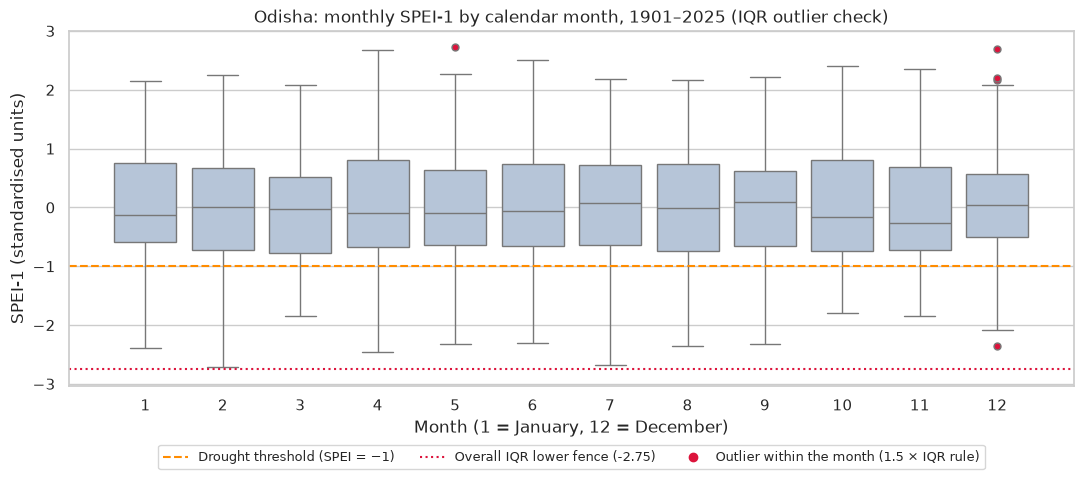

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=odisha_month, x="month", y="spei_1", color="lightsteelblue", ax=ax,
            flierprops={"marker": "o", "markerfacecolor": "crimson", "markersize": 5})
ax.axhline(DROUGHT_THRESHOLD, color="darkorange", linestyle="--", label="Drought threshold (SPEI = −1)")
ax.axhline(low_s, color="crimson", linestyle=":", label=f"Overall IQR lower fence ({low_s:.2f})")
ax.plot([], [], "o", color="crimson", label="Outlier within the month (1.5 × IQR rule)")
ax.set_title("Odisha: monthly SPEI-1 by calendar month, 1901–2025 (IQR outlier check)")
ax.set_xlabel("Month (1 = January, 12 = December)")
ax.set_ylabel("SPEI-1 (standardised units)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "fig04_odisha_spei1_boxplot_by_month.png", dpi=150)
plt.show()

**Interpretation (outliers):** With the IQR rule the Odisha **statewide** SPEI-1 series has **no outliers at all**: the fences are −2.75 and +2.79 and the values range from −2.72 (February 2006) to +2.73. The boxplot still marks a few red points, but those are only unusual *for their own calendar month*, not for the whole series. In the 30-district table the fences are −2.85 and +2.83 and **29 of 45,000 district-months (0.06%)** are outliers (13 low, 16 high); only 9 district-months have |SPEI| > 3.

We **keep** all these values and only flag them in the column `spei1_iqr_outlier`. SPEI is already a z-score, so values near ±3 are rare but possible, and they are exactly the extreme droughts (or very wet months) we want to study – deleting them would hide the most important events. Most of the 13 low district outliers line up with dry months for the whole state: September 1996 (Odisha average −2.33; Jajpur, Kendrapara, Cuttack and Bhadrak), April 1999 (Odisha −2.37; Bargarh and Jharsuguda), February 2006 (Odisha −2.72; Kendrapara and Jagatsinghpur) and May 1972 (Bhadrak, Odisha −2.31). Two cases are local only – Deogarh in July 1920 (−3.62) and Subarnapur in August 2006 (−3.00) while the Odisha average was positive (+0.85 and +2.06) – so we note them for checking later, but there is no sign of data errors such as sentinel values.

## 8. Yearly summary tables
From the monthly tables we make one row per area per year:

| Column | Meaning |
|---|---|
| `spei1_mean`, `spei1_min` | mean and lowest monthly SPEI-1 in the year |
| `drought_months` | number of months with SPEI-1 ≤ −1 (0–12) |
| `severe_or_worse_months`, `extreme_months` | months with SPEI-1 ≤ −1.5 and ≤ −2 |
| `jjas_spei1_mean`, `jjas_drought_months` | the same idea for June–September only |
| `monsoon_spei4_sep` | SPEI-4 in September = dryness of the whole JJAS monsoon |
| `monsoon_drought`, `monsoon_severity` | 1 if `monsoon_spei4_sep` ≤ −1, and its severity class |
| `annual_spei12_dec` | SPEI-12 in December = dryness of the whole calendar year |
| `annual_drought`, `annual_severity` | 1 if `annual_spei12_dec` ≤ −1, and its severity class |

In [22]:
def make_yearly(month_df, id_cols):
    df = month_df.copy()
    df["severe_or_worse"] = (df["spei_1"] <= -1.5).astype(int)
    df["extreme"] = (df["spei_1"] <= -2).astype(int)
    keys = id_cols + ["year"]

    yearly = df.groupby(keys).agg(spei1_mean=("spei_1", "mean"),
                                  spei1_min=("spei_1", "min"),
                                  drought_months=("drought", "sum"),
                                  severe_or_worse_months=("severe_or_worse", "sum"),
                                  extreme_months=("extreme", "sum"),
                                  n_months=("month", "count"))

    jjas = df[df["season"] == "Monsoon (JJAS)"].groupby(keys).agg(
        jjas_spei1_mean=("spei_1", "mean"), jjas_drought_months=("drought", "sum"))

    sep = df[df["month"] == 9].set_index(keys)["spei_4"].rename("monsoon_spei4_sep")
    dec = df[df["month"] == 12].set_index(keys)["spei_12"].rename("annual_spei12_dec")

    yearly = yearly.join(jjas).join(sep).join(dec).reset_index()
    yearly["monsoon_drought"] = (yearly["monsoon_spei4_sep"] <= DROUGHT_THRESHOLD).astype(int)
    yearly["monsoon_severity"] = pd.Categorical(yearly["monsoon_spei4_sep"].apply(severity_class),
                                                categories=SEVERITY_ORDER, ordered=True)
    yearly["annual_drought"] = (yearly["annual_spei12_dec"] <= DROUGHT_THRESHOLD).astype(int)
    yearly["annual_severity"] = pd.Categorical(yearly["annual_spei12_dec"].apply(severity_class),
                                               categories=SEVERITY_ORDER, ordered=True)
    yearly["decade"] = (yearly["year"] // 10) * 10
    return yearly


odisha_year = make_yearly(odisha_month, ["area"])
odisha_district_year = make_yearly(odisha_district_month, ["district_id", "district"])

# Every year should have 12 months, and the Sep/Dec values should never be missing
print("odisha_year         :", odisha_year.shape, "| years with != 12 months:", (odisha_year["n_months"] != 12).sum())
print("odisha_district_year:", odisha_district_year.shape, "| years with != 12 months:", (odisha_district_year["n_months"] != 12).sum())
print("Missing values in yearly tables:", int(odisha_year.isna().sum().sum()), int(odisha_district_year.isna().sum().sum()))
odisha_year.head()

odisha_year         : (125, 17) | years with != 12 months: 0
odisha_district_year: (3750, 18) | years with != 12 months: 0
Missing values in yearly tables: 0 0


,area,year,spei1_mean,spei1_min,drought_months,severe_or_worse_months,extreme_months,n_months,jjas_spei1_mean,jjas_drought_months,monsoon_spei4_sep,annual_spei12_dec,monsoon_drought,monsoon_severity,annual_drought,annual_severity,decade
0,Odisha,1901,0.108716,-2.09140,1,1,1,12,-0.833353,1,-1.71040,-0.61809,1,Severe,0,No drought,1900
1,Odisha,1902,0.006104,-1.59940,3,1,0,12,-0.371182,2,-0.63028,-0.77789,0,No drought,0,No drought,1900
2,Odisha,1903,0.441531,-0.73068,0,0,0,12,0.045275,0,-0.11715,0.81193,0,No drought,0,No drought,1900
3,Odisha,1904,-0.010140,-0.97873,0,0,0,12,0.201620,0,0.45244,-0.05831,0,No drought,0,No drought,1900
4,Odisha,1905,0.111495,-1.94840,2,1,0,12,-0.353692,1,-0.76115,-0.52604,0,No drought,0,No drought,1900


## 9. Initial exploratory data analysis

### 9.1 Descriptive statistics

In [23]:
odisha_month[SPEI_COLS].describe().round(3)

,spei_1,spei_4,spei_12
count,1500.000,1497.000,1489.000
mean,-0.000,0.000,-0.000
std,0.996,0.996,0.996
min,-2.717,-3.146,-2.834
25%,-0.676,-0.662,-0.615
50%,-0.043,0.005,0.019
75%,0.709,0.693,0.678
max,2.728,2.683,2.926


In [24]:
# Skewness tells us if the distribution leans to one side (0 = symmetric)
pd.DataFrame({"odisha_district_month": odisha_district_month[SPEI_COLS].skew(),
              "odisha_statewide": odisha_month[SPEI_COLS].skew()}).round(3)

,odisha_district_month,odisha_statewide
spei_1,0.149,0.027
spei_4,-0.000,-0.097
spei_12,-0.018,-0.119


In [25]:
# How often does each severity class happen? (percentage of all months)
sev_share = pd.DataFrame({
    "Odisha statewide (%)": odisha_month["severity"].value_counts(normalize=True).sort_index() * 100,
    "Odisha districts (%)": odisha_district_month["severity"].value_counts(normalize=True).sort_index() * 100,
}).round(2)
sev_share

,Odisha statewide (%),Odisha districts (%)
severity,,
No drought,83.80,83.98
Moderate,9.07,9.99
Severe,5.27,4.54
Extreme,1.87,1.49


In [26]:
# Odisha summary numbers used in the text below
odisha = odisha_month
print("Odisha drought months (SPEI-1 <= -1):", odisha["drought"].sum(), "of", len(odisha),
      f"= {odisha['drought'].mean() * 100:.1f}%")
print("Odisha monsoon drought years (Sep SPEI-4 <= -1):", odisha_year["monsoon_drought"].sum(), "of", len(odisha_year))
print("Odisha calendar-year droughts (Dec SPEI-12 <= -1):", odisha_year["annual_drought"].sum(), "of", len(odisha_year))
print()
print("Driest monsoon seasons in Odisha (lowest September SPEI-4):")
display(odisha_year.nsmallest(8, "monsoon_spei4_sep")[["year", "monsoon_spei4_sep", "monsoon_severity",
                                                        "annual_spei12_dec", "drought_months"]])

Odisha drought months (SPEI-1 <= -1): 243 of 1500 = 16.2%
Odisha monsoon drought years (Sep SPEI-4 <= -1): 20 of 125
Odisha calendar-year droughts (Dec SPEI-12 <= -1): 18 of 125

Driest monsoon seasons in Odisha (lowest September SPEI-4):


,year,monsoon_spei4_sep,monsoon_severity,annual_spei12_dec,drought_months
73,1974,-2.8797,Extreme,-2.80450,4
86,1987,-2.5587,Extreme,-1.75080,3
78,1979,-2.1736,Extreme,-2.72220,5
64,1965,-2.0693,Extreme,-2.14130,3
101,2002,-1.8250,Severe,-2.14200,4
23,1924,-1.7913,Severe,-0.73374,4
0,1901,-1.7104,Severe,-0.61809,1
97,1998,-1.6548,Severe,-0.28529,2


### 9.2 Distribution of SPEI-1 in Odisha

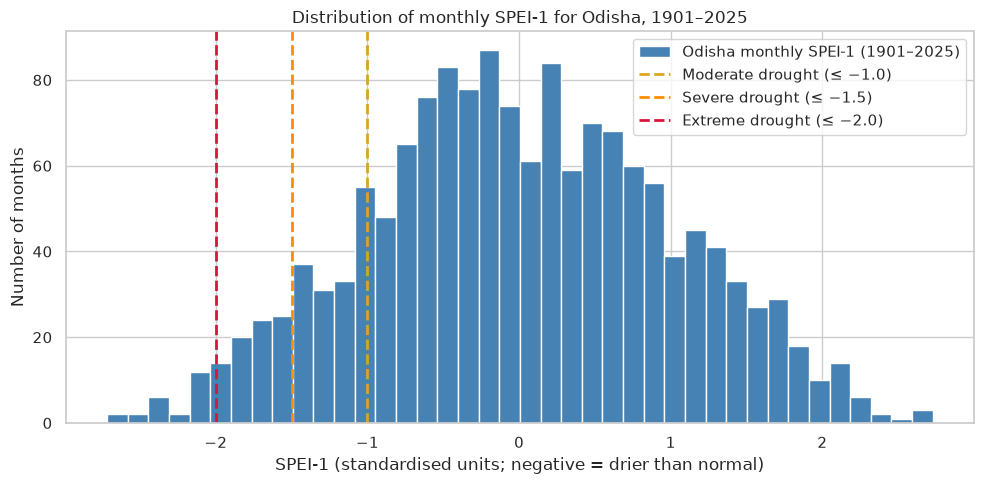

min SPEI-1: [Timestamp('2006-02-01 00:00:00'), np.float64(-2.7172)] | skew: 0.03 | mean: -0.0 | std: 0.996


In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(odisha["spei_1"], bins=40, color="steelblue", edgecolor="white", label="Odisha monthly SPEI-1 (1901–2025)")
ax.axvline(-1.0, color="goldenrod", linestyle="--", linewidth=2, label="Moderate drought (≤ −1.0)")
ax.axvline(-1.5, color="darkorange", linestyle="--", linewidth=2, label="Severe drought (≤ −1.5)")
ax.axvline(-2.0, color="crimson", linestyle="--", linewidth=2, label="Extreme drought (≤ −2.0)")
ax.set_title("Distribution of monthly SPEI-1 for Odisha, 1901–2025")
ax.set_xlabel("SPEI-1 (standardised units; negative = drier than normal)")
ax.set_ylabel("Number of months")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "fig01_odisha_spei1_histogram.png", dpi=150)
plt.show()
print("min SPEI-1:", odisha.loc[odisha["spei_1"].idxmin(), ["date", "spei_1"]].tolist(), "| skew:", round(odisha["spei_1"].skew(), 2),
      "| mean:", round(odisha["spei_1"].mean(), 3), "| std:", round(odisha["spei_1"].std(), 3))

**Interpretation:** Odisha's monthly SPEI-1 is roughly bell-shaped and centred on 0 (mean ≈ 0, standard deviation 1.0, skewness 0.03), which is what we expect from a standardised index. 243 of the 1500 months (16.2%) are at or below −1, 107 months are severe or worse (≤ −1.5) and 28 months reach the extreme class (≤ −2). The lowest value is −2.72 (February 2006), so there is no long tail of strange values.

### 9.3 Odisha SPEI over time
Monthly SPEI-1 jumps up and down a lot, so for the long time series we plot **SPEI-12**, which shows the dryness
of the previous 12 months and is smoother.

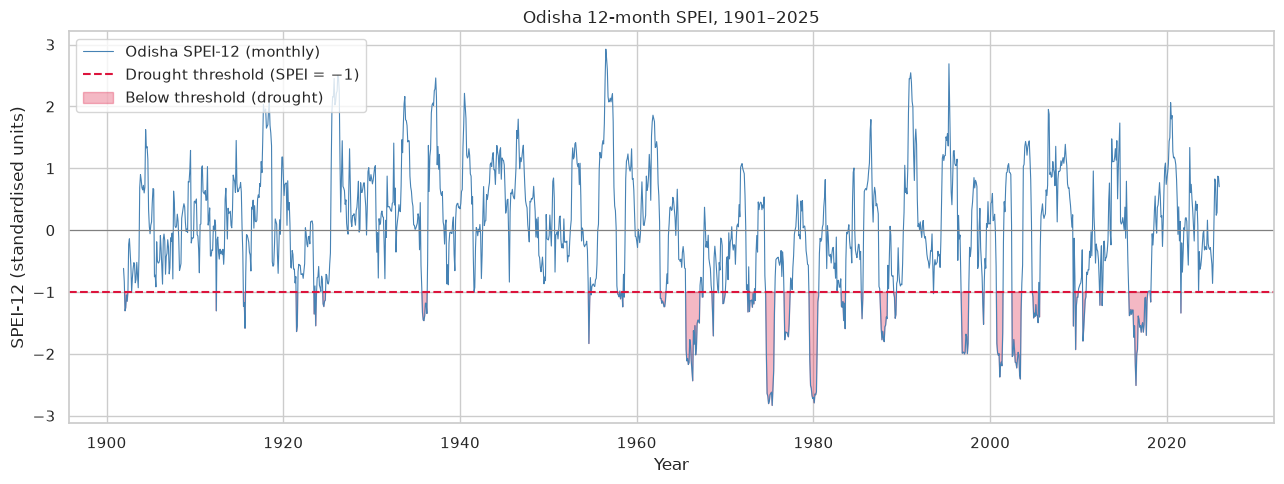

In [28]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(odisha["date"], odisha["spei_12"], color="steelblue", linewidth=0.8, label="Odisha SPEI-12 (monthly)")
ax.axhline(0, color="grey", linewidth=0.8)
ax.axhline(DROUGHT_THRESHOLD, color="crimson", linestyle="--", label="Drought threshold (SPEI = −1)")
ax.fill_between(odisha["date"], odisha["spei_12"], DROUGHT_THRESHOLD,
                where=odisha["spei_12"] <= DROUGHT_THRESHOLD, interpolate=True, color="crimson", alpha=0.3,
                label="Below threshold (drought)")
ax.set_title("Odisha 12-month SPEI, 1901–2025")
ax.set_xlabel("Year")
ax.set_ylabel("SPEI-12 (standardised units)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "fig02_odisha_spei12_timeseries.png", dpi=150)
plt.show()

In [29]:
# Numbers for the interpretation: share of months with SPEI-12 <= -1, before and after 1960
for label, part in [("1901-1960", odisha[odisha["year"] <= 1960]), ("1961-2025", odisha[odisha["year"] > 1960])]:
    share = (part["spei_12"] <= DROUGHT_THRESHOLD).mean() * 100
    print(f"{label}: {share:.1f}% of months have SPEI-12 <= -1, mean SPEI-12 = {part['spei_12'].mean():.2f}")
dec12 = odisha_year.nsmallest(3, "annual_spei12_dec")[["year", "annual_spei12_dec"]].round(2)
print("Lowest December SPEI-12:", dec12.values.tolist())
# Periods when SPEI-12 stays <= -1 for 6+ months in a row
s = (odisha["spei_12"] <= -1)
run = (s != s.shift()).cumsum()
long_runs = odisha[s].groupby(run[s]).agg(start=("date", "first"), end=("date", "last"), months=("date", "size"))
print(long_runs[long_runs["months"] >= 6][["start", "end", "months"]].assign(start=lambda d: d.start.dt.strftime("%Y-%m"), end=lambda d: d.end.dt.strftime("%Y-%m")).to_string())

1901-1960: 5.1% of months have SPEI-12 <= -1, mean SPEI-12 = 0.28
1961-2025: 24.4% of months have SPEI-12 <= -1, mean SPEI-12 = -0.26
Lowest December SPEI-12: [[1974.0, -2.8], [1979.0, -2.72], [2002.0, -2.14]]
           start      end  months
spei_12                          
18       1935-10  1936-04       7
32       1962-09  1963-04       8
34       1965-08  1967-02      19
46       1972-10  1973-04       7
50       1974-08  1975-08      13
52       1976-09  1977-05       9
54       1979-07  1980-08      14
56       1983-03  1983-08       6
60       1987-08  1988-05      10
66       1996-10  1997-07      10
70       2000-10  2001-06       9
72       2002-07  2003-07      13
74       2004-11  2005-06       8
88       2015-10  2017-11      26


**Interpretation:** Before 1960 the 12-month SPEI for Odisha rarely goes below −1 (only 5.1% of months in 1901–1960), but after 1960 dry spells are much more common (24.4% of months in 1961–2025), and the average SPEI-12 changes from +0.28 to −0.26. The longest spells with SPEI-12 below −1 are 2015-10 to 2017-11 (26 months), 1965-08 to 1967-02 (19 months), 1979-07 to 1980-08 (14 months), 1974-08 to 1975-08 and 2002-07 to 2003-07 (13 months each). The three lowest December SPEI-12 values are 1974 (−2.80), 1979 (−2.72) and 2002 (−2.14); 1974 and 1979 are also among the driest monsoon seasons in the table in 9.1.

### 9.4 Drought months per decade in Odisha
The 2020s contain only 6 years (2020–2025), so we plot the **percentage** of months in drought in each decade instead of
raw counts. The 1900s contain only 9 years (1901–1909). If SPEI followed a perfect normal distribution, about 15.9% of months would be below −1; we draw that as a
reference line.

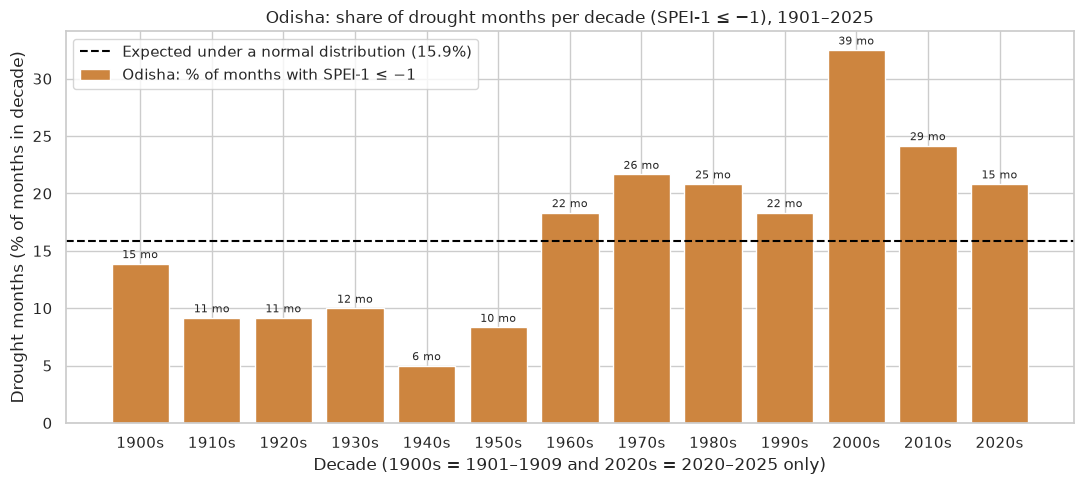

,drought_months,months,drought_%
decade,,,
1900,15,108,13.9
1910,11,120,9.2
1920,11,120,9.2
1930,12,120,10.0
1940,6,120,5.0
1950,10,120,8.3
1960,22,120,18.3
1970,26,120,21.7
1980,25,120,20.8


In [30]:
decade_stats = odisha.groupby("decade").agg(drought_months=("drought", "sum"), months=("drought", "count"))
decade_stats["drought_%"] = decade_stats["drought_months"] / decade_stats["months"] * 100

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(decade_stats.index.astype(str) + "s", decade_stats["drought_%"], color="peru",
              label="Odisha: % of months with SPEI-1 ≤ −1")
ax.bar_label(bars, labels=decade_stats["drought_months"].astype(str) + " mo", fontsize=8, padding=2)
ax.axhline(15.87, color="black", linestyle="--", label="Expected under a normal distribution (15.9%)")
ax.set_title("Odisha: share of drought months per decade (SPEI-1 ≤ −1), 1901–2025")
ax.set_xlabel("Decade (1900s = 1901–1909 and 2020s = 2020–2025 only)")
ax.set_ylabel("Drought months (% of months in decade)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "fig03_odisha_drought_months_per_decade.png", dpi=150)
plt.show()
decade_stats.round(1)

In [31]:
# Compare the first 60 years with the rest, for the statewide series and for the pooled district-months
compare = []
for label, df in [("Odisha statewide", odisha), ("30 districts pooled", odisha_district_month)]:
    compare.append({"area": label,
                    "drought_% 1901-1960": round(df.loc[df["year"] <= 1960, "drought"].mean() * 100, 1),
                    "drought_% 1961-2025": round(df.loc[df["year"] > 1960, "drought"].mean() * 100, 1)})
pd.DataFrame(compare)

,area,drought_% 1901-1960,drought_% 1961-2025
0,Odisha statewide,9.4,22.4
1,30 districts pooled,9.7,21.9


**Interpretation:** From the 1900s to the 1950s Odisha had fewer drought months than the normal expectation (from 5.0% in the 1940s to 13.9% in 1901–1909). From the 1960s onwards every decade is above 15.9%, and the 2000s are the worst with 39 drought months (32.5%), followed by the 2010s (29 months, 24.2%). Overall 9.4% of months were in drought in 1901–1960 against 22.4% in 1961–2025. The 30 districts pooled give almost the same picture (9.7% → 21.9%), so the statewide series is a fair summary of the districts. We test this change formally in notebook 02.

### 9.5 Odisha districts: drought share, full period vs recent period
A first look at which Odisha districts are most drought-prone. We compare the full record (1901–2025) with the
most recent 35 years (1991–2025).

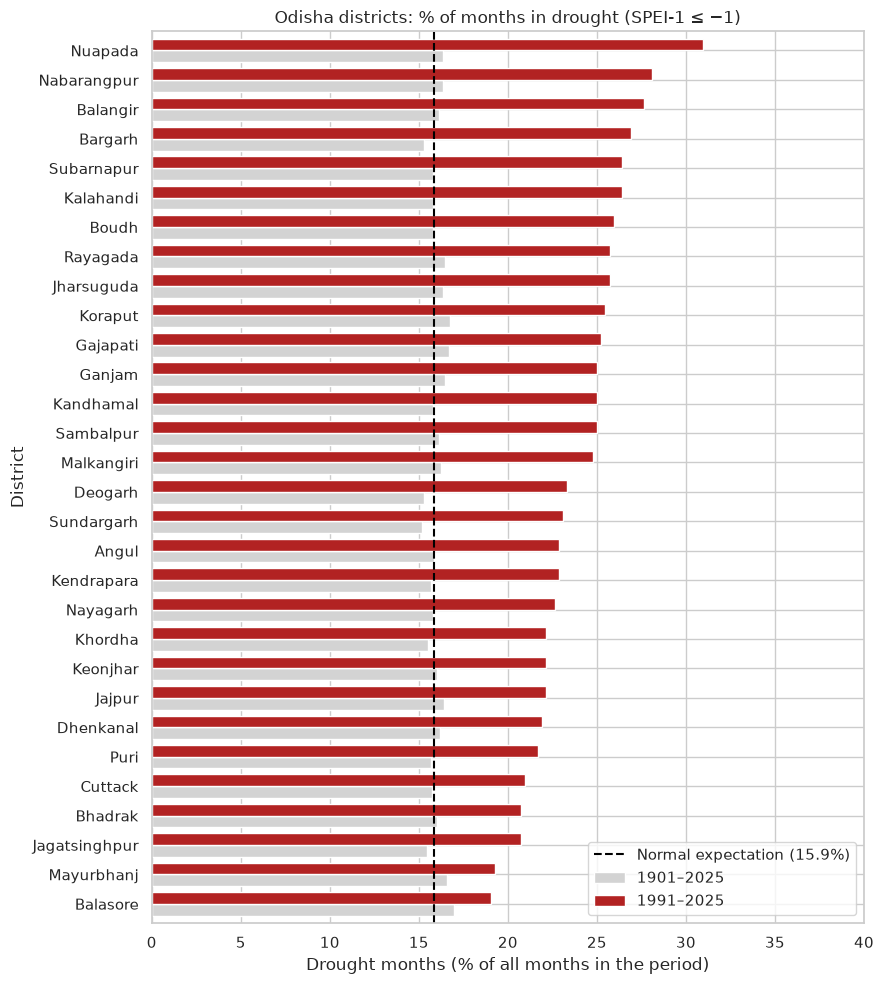

Full-period share range: 15.2 to 17.0


,1901–2025,1991–2025
district,,
Nuapada,16.3,31.0
Nabarangpur,16.3,28.1
Balangir,16.1,27.6
Bargarh,15.3,26.9
Kalahandi,15.8,26.4
Subarnapur,15.8,26.4
Boudh,15.8,26.0
Jharsuguda,16.3,25.7
Rayagada,16.5,25.7


In [32]:
full = odisha_district_month.groupby("district")["drought"].mean() * 100
recent = odisha_district_month[odisha_district_month["year"] >= 1991].groupby("district")["drought"].mean() * 100
district_share = pd.DataFrame({"1901–2025": full, "1991–2025": recent}).sort_values("1991–2025")

fig, ax = plt.subplots(figsize=(9, 10))
district_share.plot(kind="barh", ax=ax, color=["lightgrey", "firebrick"], width=0.8)
ax.axvline(15.87, color="black", linestyle="--", label="Normal expectation (15.9%)")
ax.set_title("Odisha districts: % of months in drought (SPEI-1 ≤ −1)")
ax.set_xlabel("Drought months (% of all months in the period)")
ax.set_ylabel("District")
ax.set_xlim(0, 40)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "fig05_odisha_districts_drought_share.png", dpi=150)
plt.show()
print("Full-period share range:", round(full.min(), 1), "to", round(full.max(), 1))
district_share.sort_values("1991–2025", ascending=False).round(1).head(10)

In [33]:
# Same idea with the monsoon indicator: number of years with September SPEI-4 <= -1
monsoon_counts = pd.DataFrame({
    "monsoon_drought_years_1901_2025": odisha_district_year.groupby("district")["monsoon_drought"].sum(),
    "monsoon_drought_years_1991_2025": odisha_district_year[odisha_district_year["year"] >= 1991]
                                        .groupby("district")["monsoon_drought"].sum(),
}).sort_values("monsoon_drought_years_1991_2025", ascending=False)
monsoon_counts.head(10)

,monsoon_drought_years_1901_2025,monsoon_drought_years_1991_2025
district,,
Bargarh,24,13
Sambalpur,24,11
Subarnapur,24,11
Sundargarh,21,10
Jharsuguda,21,10
Boudh,22,10
Nuapada,21,9
Angul,25,8
Keonjhar,24,8


**Interpretation:** Over the full 125 years every Odisha district has about 15–17% drought months (15.2% to 17.0%). This is expected, because each SPEI series is standardised over its own record (mean 0, standard deviation 1), so the full-period share **cannot** be used to rank districts. The recent period is more useful: in 1991–2025 all 30 districts are above 15.9%, and the highest shares are in western and southern Odisha – Nuapada (31.0%), Nabarangpur (28.1%), Balangir (27.6%) and Bargarh (26.9%) – while Balasore (19.0%) and Mayurbhanj (19.3%) in the north-east are the lowest. The monsoon indicator gives a similar picture: since 1991, Bargarh had 13 monsoon drought years (September SPEI-4 ≤ −1), and Sambalpur and Subarnapur had 11 each.

## 10. Saving the cleaned data
We save the cleaned tables as CSV files (without the pandas index). We also save the name lookup table so anyone can
see how each original atlas name was changed. **Only Odisha tables are saved.**

In [34]:
# Column order for the monthly tables
month_cols = ["date", "year", "month", "decade", "season"] + SPEI_COLS + ["drought", "severity", "spei1_iqr_outlier"]

outputs = {
    "odisha_month.csv": odisha_month[["area"] + month_cols],
    "odisha_year.csv": odisha_year,
    "odisha_district_month.csv": odisha_district_month[["district_id", "district", "district_name_raw"] + month_cols],
    "odisha_district_year.csv": odisha_district_year,
    "lookup_odisha_districts_clean.csv": dist_clean[["district_id", "district_name_raw", "district"]],
}

saved = []
for file_name, table in outputs.items():
    path = CLEAN / file_name
    table.to_csv(path, index=False)
    saved.append({"file": f"data/clean/{file_name}", "rows": table.shape[0], "columns": table.shape[1],
                  "size_KB": round(path.stat().st_size / 1024, 1)})
pd.DataFrame(saved)

,file,rows,columns,size_KB
0,data/clean/odisha_month.csv,1500,12,125.3
1,data/clean/odisha_year.csv,125,17,13.8
2,data/clean/odisha_district_month.csv,45000,14,4488.8
3,data/clean/odisha_district_year.csv,3750,18,427.5
4,data/clean/lookup_odisha_districts_clean.csv,30,3,0.7


In [35]:
# Read one file back to make sure it saved correctly
check = pd.read_csv(CLEAN / "odisha_district_month.csv", parse_dates=["date"])
print(check.shape, "| districts:", check["district"].nunique(), "| missing SPEI-1:", check["spei_1"].isna().sum())
pd.DataFrame(shape_log + [("odisha (state)", "final odisha_month.csv", odisha_month[["area"] + month_cols].shape),
                          ("district", "final odisha_district_month.csv", odisha_district_month[["district_id", "district", "district_name_raw"] + month_cols].shape)],
             columns=["table", "step", "shape (rows, cols)"])

(45000, 14) | districts: 30 | missing SPEI-1: 0


,table,step,"shape (rows, cols)"
0,odisha (state),raw (Odisha state file),"(1500, 6)"
1,odisha (state),after adding the area name and sorting,"(1500, 6)"
2,district,raw (30 Odisha district files),"(45000, 6)"
3,district,after adding names (join on ID),"(45000, 8)"
4,odisha (state),final odisha_month.csv,"(1500, 12)"
5,district,final odisha_district_month.csv,"(45000, 14)"


## 11. Summary of notebook 01

### Cleaned files (in `data/clean/`)
| File | Rows × columns | One row = |
|---|---|---|
| `odisha_month.csv` | 1,500 × 12 | Odisha statewide series, one month |
| `odisha_year.csv` | 125 × 17 | Odisha statewide, one year |
| `odisha_district_month.csv` | 45,000 × 14 | one Odisha district, one month (30 × 1500) |
| `odisha_district_year.csv` | 3,750 × 18 | one Odisha district, one year (30 × 125) |
| `lookup_odisha_districts_clean.csv` | 30 × 3 | original name → cleaned name |

### Key cleaning decisions
1. Used only the `Z-score` Odisha state file and the 30 Odisha district files (as planned in the proposal); the 6.2 GB gridded files and the other atlas files were not used.
2. No empty series, no sentinel values, no duplicates and no missing months were found in the Odisha data, so nothing had to be removed for those reasons.
3. Kept the structural NaN values of SPEI-4 (Jan–Mar 1901) and SPEI-12 (Jan–Nov 1901) without filling them.
4. Repaired corrupted names (`@` → U in `MAY@RBHANJ` and `N@APARHA`) and gave Odisha districts their common spellings, keeping the original names.
5. Kept extreme SPEI values (IQR outliers) because they are real drought/wet events, and flagged them in `spei1_iqr_outlier`.

### Early findings
1. Odisha (statewide series) was in drought (SPEI-1 ≤ −1) in 243 of 1500 months (16.2%); 28 of those months were extreme (≤ −2).
2. Drought months became much more frequent after 1960: 9.4% of months in 1901–1960 vs 22.4% in 1961–2025; the 2000s were the worst decade (39 months, 32.5%).
3. The driest monsoon seasons (September SPEI-4) were 1974 (−2.88), 1987 (−2.56), 1979 (−2.17) and 1965 (−2.07); Odisha had 20 monsoon-drought years and 18 calendar-year droughts in 125 years.
4. In 1991–2025 the western/southern districts Nuapada (31.0%), Nabarangpur (28.1%), Balangir (27.6%) and Bargarh (26.9%) had the highest share of drought months; Bargarh also had the most monsoon drought years (13).
5. Because every SPEI series is standardised over its own record, full-period drought percentages are all close to 16%. To rank districts fairly we compare periods (recent vs early) or use severity, not just the full-period count.

### Next steps
- Notebook 02: trends, district rankings, West vs Coastal tests, seasonality and spatial coherence between districts.
- Notebook 03: district maps and publication-style charts.